In [1]:
import torch
from torch import nn
torch.manual_seed(42)

class VectorQuantizer(nn.Module):
    def __init__(self, num_embeddings=64, embedding_dim=16, beta=0.25):
        super().__init__()

        self.beta = beta # あと使うハイパーパラメータ
        self.codebook = nn.Embedding(num_embeddings, embedding_dim) # 辞書のオブジェクト、num_embeddings 個の embedding_dim サイズのベクトルによって構成したテーブル

        nn.init.uniform_(self.codebook.weight, -1 / num_embeddings, 1 / num_embeddings,) # 辞書を初期化する

In [2]:
vq = VectorQuantizer(num_embeddings=2, embedding_dim=8)
print("辞書の中身：")
print(vq.codebook.weight)

print("\n要素を取り出してみよう:")
print(vq.codebook(torch.tensor(0)))

辞書の中身：
Parameter containing:
tensor([[ 0.3854,  0.0739, -0.2334,  0.1274, -0.2304, -0.0586, -0.2031,  0.3317],
        [-0.3947, -0.2305, -0.1412, -0.3006,  0.0472, -0.4938,  0.4516, -0.4247]],
       requires_grad=True)

要素を取り出してみよう:
tensor([ 0.3854,  0.0739, -0.2334,  0.1274, -0.2304, -0.0586, -0.2031,  0.3317],
       grad_fn=<EmbeddingBackward0>)


In [3]:

class VectorQuantizer(nn.Module):
    def __init__(self, num_embeddings=64, embedding_dim=16, beta=0.25):
        super().__init__()
        self.beta = beta
        self.codebook = nn.Embedding(num_embeddings, embedding_dim)
        nn.init.uniform_(self.codebook.weight, -1, 1)

    def forward(self, x):
        # x: [B, H]
        # codebook: [N, H]
        # squared_distances: [B, N]
        squared_distances = (
            self.codebook.weight.unsqueeze(0) - x.unsqueeze(1)
        ).square().sum(dim=-1)

        indices = squared_distances.argmin(dim=1)
        return self.codebook(indices), indices


vq = VectorQuantizer(num_embeddings=10, embedding_dim=2)

print("辞書の中身：")
print(vq.codebook.weight)

print("\n一番近いやつを探す:")
x = torch.tensor([
    [0.2, 0.1],
    [0.5, 0.5],
    [-0.5, 0.3]
])

with torch.no_grad():
    quantized, indices = vq(x)
    print(quantized)

辞書の中身：
Parameter containing:
tensor([[-0.5964, -0.5964],
        [ 0.8994,  0.3333],
        [ 0.9623, -0.8253],
        [-0.9919, -0.7824],
        [-0.6727,  0.4050],
        [ 0.3581,  0.8309],
        [-0.5164, -0.6817],
        [ 0.5306, -0.4042],
        [ 0.6069, -0.2373],
        [ 0.5720, -0.7770]], requires_grad=True)

一番近いやつを探す:
tensor([[ 0.6069, -0.2373],
        [ 0.3581,  0.8309],
        [-0.6727,  0.4050]])


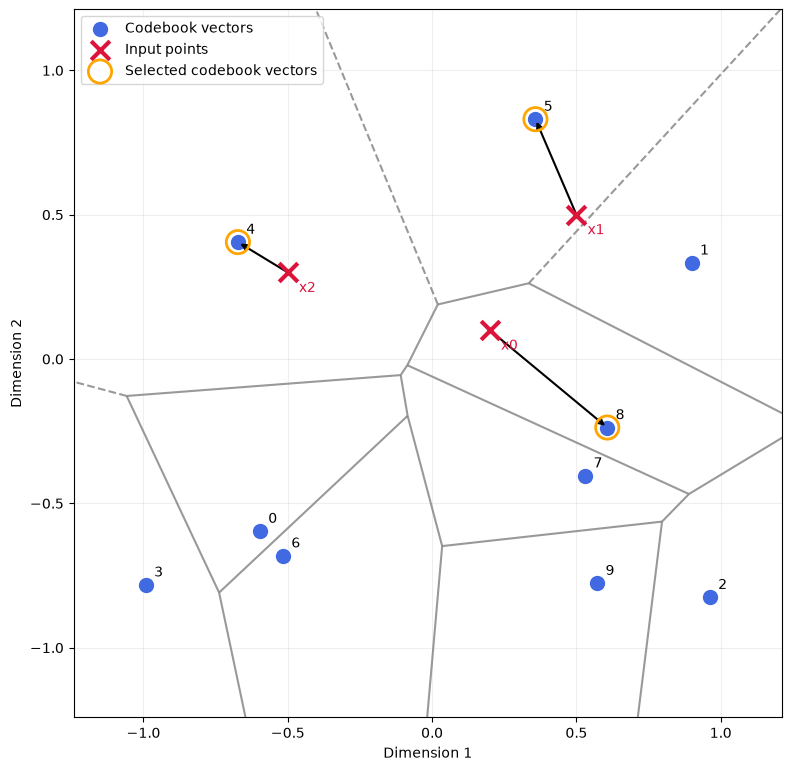

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Voronoi, voronoi_plot_2d

codebook = vq.codebook.weight.detach().cpu().numpy()
inputs = x.detach().cpu().numpy()
matches = quantized.detach().cpu().numpy()

# Square figure with a 1:1 coordinate ratio.
fig, ax = plt.subplots(figsize=(8, 8))

# Voronoi boundaries: each region belongs to its nearest embedding.
vor = Voronoi(codebook)
voronoi_plot_2d(
    vor,
    ax=ax,
    show_points=False,
    show_vertices=False,
    line_colors="gray",
    line_width=1.5,
    line_alpha=0.8,
)

ax.scatter(
    codebook[:, 0], codebook[:, 1],
    s=100, color="royalblue",
    label="Codebook vectors", zorder=3,
)

for i, point in enumerate(codebook):
    ax.annotate(
        str(i), point,
        xytext=(6, 6), textcoords="offset points",
    )

ax.scatter(
    inputs[:, 0], inputs[:, 1],
    s=180, color="crimson", marker="x",
    linewidths=3, label="Input points", zorder=5,
)

ax.scatter(
    matches[:, 0], matches[:, 1],
    s=280, facecolors="none", edgecolors="orange",
    linewidths=2, label="Selected codebook vectors", zorder=4,
)

for i, (point, match) in enumerate(zip(inputs, matches)):
    ax.annotate(
        "", xy=match, xytext=point,
        arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
    )
    ax.annotate(
        f"x{i}", point,
        xytext=(8, -14), textcoords="offset points",
        color="crimson",
    )

# Identical limits ensure a square plotting area.
all_points = np.vstack([codebook, inputs])
lower = all_points.min() - 0.25
upper = all_points.max() + 0.25

ax.set_xlim(lower, upper)
ax.set_ylim(lower, upper)
ax.set_aspect("equal", adjustable="box")
ax.set_box_aspect(1)

ax.set_xlabel("Dimension 1")
ax.set_ylabel("Dimension 2")
ax.grid(alpha=0.2)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

In [9]:
vq = VectorQuantizer(num_embeddings=64, embedding_dim=2)

print("辞書の中身：")
print(vq.codebook.weight)

print("\n一番近いやつを探す:")
x = torch.tensor([
    [0.2, 0.1],
    [0.5, 0.5],
    [-0.5, 0.3]
])

with torch.no_grad():
    quantized, indices = vq(x)
    print(quantized)

辞書の中身：
Parameter containing:
tensor([[ 0.4701,  0.9168],
        [ 0.3588, -0.3940],
        [-0.9364,  0.3622],
        [-0.4955,  0.5089],
        [ 0.6685,  0.3857],
        [ 0.9383,  0.9498],
        [ 0.2117, -0.7286],
        [ 0.8934, -0.4745],
        [-0.4724,  0.8368],
        [ 0.7748,  0.3022],
        [ 0.0627, -0.8412],
        [-0.1038,  0.9591],
        [ 0.2547,  0.0856],
        [-0.2077, -0.3488],
        [ 0.5960,  0.0617],
        [ 0.6506, -0.1770],
        [ 0.4369,  0.4128],
        [ 0.1595,  0.6284],
        [ 0.6266,  0.9269],
        [ 0.7688, -0.2557],
        [-0.8466,  0.1828],
        [-0.0087, -0.2608],
        [-0.1675,  0.0470],
        [ 0.7296,  0.3117],
        [-0.3551, -0.4112],
        [-0.2476, -0.3865],
        [ 0.8992,  0.5296],
        [ 0.9030,  0.0032],
        [ 0.2017,  0.3468],
        [-0.9466,  0.0893],
        [-0.0669, -0.5607],
        [-0.7759,  0.8853],
        [ 0.8131,  0.4635],
        [ 0.9542, -0.4058],
        [-0.1727,  

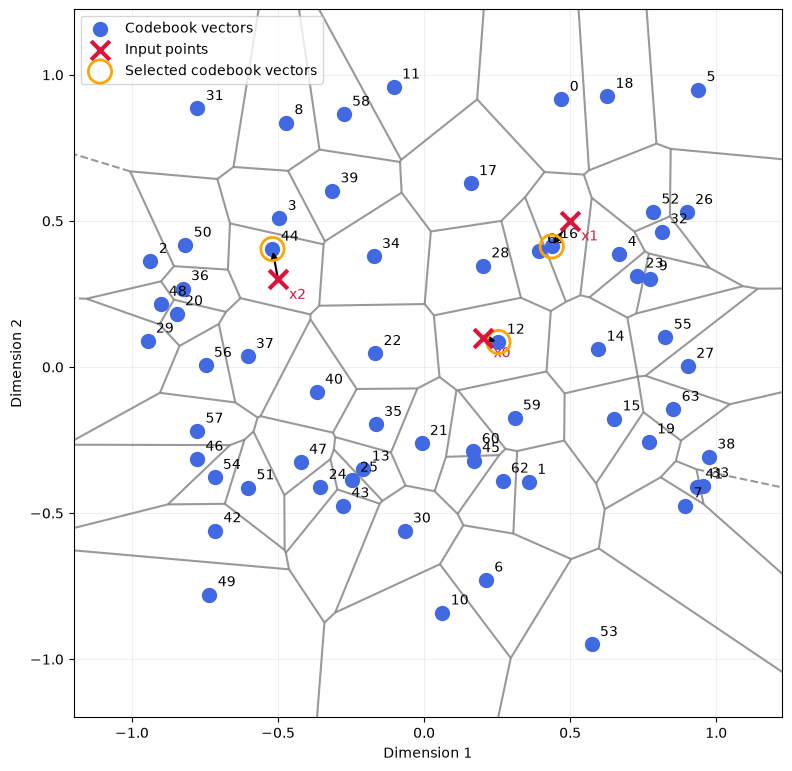

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import Voronoi, voronoi_plot_2d

codebook = vq.codebook.weight.detach().cpu().numpy()
inputs = x.detach().cpu().numpy()
matches = quantized.detach().cpu().numpy()

# Square figure with a 1:1 coordinate ratio.
fig, ax = plt.subplots(figsize=(8, 8))

# Voronoi boundaries: each region belongs to its nearest embedding.
vor = Voronoi(codebook)
voronoi_plot_2d(
    vor,
    ax=ax,
    show_points=False,
    show_vertices=False,
    line_colors="gray",
    line_width=1.5,
    line_alpha=0.8,
)

ax.scatter(
    codebook[:, 0], codebook[:, 1],
    s=100, color="royalblue",
    label="Codebook vectors", zorder=3,
)

for i, point in enumerate(codebook):
    ax.annotate(
        str(i), point,
        xytext=(6, 6), textcoords="offset points",
    )

ax.scatter(
    inputs[:, 0], inputs[:, 1],
    s=180, color="crimson", marker="x",
    linewidths=3, label="Input points", zorder=5,
)

ax.scatter(
    matches[:, 0], matches[:, 1],
    s=280, facecolors="none", edgecolors="orange",
    linewidths=2, label="Selected codebook vectors", zorder=4,
)

for i, (point, match) in enumerate(zip(inputs, matches)):
    ax.annotate(
        "", xy=match, xytext=point,
        arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
    )
    ax.annotate(
        f"x{i}", point,
        xytext=(8, -14), textcoords="offset points",
        color="crimson",
    )

# Identical limits ensure a square plotting area.
all_points = np.vstack([codebook, inputs])
lower = all_points.min() - 0.25
upper = all_points.max() + 0.25

ax.set_xlim(lower, upper)
ax.set_ylim(lower, upper)
ax.set_aspect("equal", adjustable="box")
ax.set_box_aspect(1)

ax.set_xlabel("Dimension 1")
ax.set_ylabel("Dimension 2")
ax.grid(alpha=0.2)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()